In [4]:
from maxent_insect_dir import config
from maxent_insect_dir.data_utils import safe_read_file
import numpy as np 
import pandas as pd
import rasterio
import geopandas as gpd
from shapely.geometry import Point

import matplotlib.pyplot as plt
import os

In [2]:
config.config_raw

{'insect': {'EDD': {'Brown_Marmorated_Stink_bug': PosixPath('/data/Maxent/data/raw/Species Data/Guna/EDD Maps Site/Brown_Marmorated_Stink_Bug - (Halyomorpha_halys) (1999_2023).gpkg'),
   'Corn_Earworm': PosixPath('/data/Maxent/data/raw/Species Data/Guna/EDD Maps Site/Corn_Earworm - (Helicoverpa_Zea) (2004-2023).gpkg'),
   'Large_Lady_Beetle': PosixPath('/data/Maxent/data/raw/Species Data/Guna/EDD Maps Site/Large_Lady_Beetle - (Harmonia_Axyridis) (1995-2023).gpkg')},
  'GBIF': {'Brown_Marmorated_Stink_bug_2': PosixPath('/data/Maxent/data/raw/Species Data/Guna/GBIF Site/Brown_Marmorated_Stink_Bug -  (Halyomorpha_halys) (2007-2023).gpkg'),
   'Root_Weevil': PosixPath('/data/Maxent/data/raw/Species Data/Guna/GBIF Site/Root_Weevil - (Diaprepes_abbreviatus) (2012-2023).gpkg')}},
 'climate_data': PosixPath('/home/pc19d/postdoc/MaxEnt_insect_dir/data/raw/worldclim_monthly/wc2.1_10m_tmin'),
 'crop_data': {'2008': PosixPath('/data/Maxent/data/raw/crop_data/2008_30m_cdls/2008_30m_cdls.tif'),
  '2

In [5]:
raster_path = config.config_raw['crop_data']['2008']
point_layer = config.config_raw['insect']['EDD']['Brown_Marmorated_Stink_bug']

# Load the point layer using geopandas (assuming the point layer is in a shapefile)
points = safe_read_file(point_layer)


# Load the raster file using rasterio
with rasterio.open(raster_path) as src:

    # Reproject points to match the CRS of the raster if needed
    points = points.to_crs(src.crs)

    # Sample raster values at point coordinates
    points['crop_code'] = [
        list(src.sample([(geom.x, geom.y)]))[0][0] if geom.is_valid else None
        for geom in points.geometry
    ]

# Now points dataframe has a column with the raster values at each point location
points.head(2)

/home/pc19d/anaconda3/envs/postdoc/lib/python3.12/site-packages/pyogrio/geopandas.py:261: UserWarning: More than one layer found in 'Brown_Marmorated_Stink_Bug - (Halyomorpha_halys) (1999_2023).gpkg': 'PointLayer' (default), 'PolygonLayer', 'LineLayer'. Specify layer parameter to avoid this warning.
  result = read_func(


,objectid,reporter,RecOwner,SciName,ComName,Nativity,OccStatus,Status,ObsDate,DateEnt,...,Locality,Comments,ReviewDate,Reviewer,VerifyMthd,Verified,IDCred,ReviewComm,geometry,crop_code
0,2001093,Chester Karwatowski Cornell Cooperative Extension,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,04-11-11,01-11-12,...,None,"""blackberry photo uploaded via web form""",11-01-17,Peter Jentsch,Bulk Verified,Verified,Credible,"""Thank you for your submission and image to E...",POINT (1772184.563 2310031.131),141
1,2001094,Chester Karwatowski Cornell Cooperative Extension,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,04-11-11,01-11-12,...,None,"""blackberry via web upload. samples taken""",11-01-17,Peter Jentsch,Bulk Verified,Verified,Credible,"""Thank you for your submission and image to E...",POINT (1783089.209 2325850.4),141


In [8]:
#load crop mapping
crop_mapping = pd.read_csv(config.config_raw['crop_config'])
# Create a mapping dictionary
crop_mapping_dict = dict(zip(crop_mapping['Code'], crop_mapping['Crop']))

In [30]:
points.head(2)

,objectid,reporter,RecOwner,SciName,ComName,Nativity,OccStatus,Status,ObsDate,DateEnt,...,Locality,Comments,ReviewDate,Reviewer,VerifyMthd,Verified,IDCred,ReviewComm,geometry,crop_code
0,2001093,Chester Karwatowski Cornell Cooperative Extension,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,04-11-11,01-11-12,...,None,"""blackberry photo uploaded via web form""",11-01-17,Peter Jentsch,Bulk Verified,Verified,Credible,"""Thank you for your submission and image to E...",POINT (1772184.563 2310031.131),141
1,2001094,Chester Karwatowski Cornell Cooperative Extension,General Public,Halyomorpha halys,brown marmorated stink bug,Introduced,Detected,Positive,04-11-11,01-11-12,...,None,"""blackberry via web upload. samples taken""",11-01-17,Peter Jentsch,Bulk Verified,Verified,Credible,"""Thank you for your submission and image to E...",POINT (1783089.209 2325850.4),141


In [45]:
points.shape

(13797, 81)

In [49]:
points.nunique()

objectid      13797
reporter        931
RecOwner         14
SciName           1
ComName           1
              ...  
Verified          2
IDCred            8
ReviewComm      297
geometry      13161
crop_code        29
Length: 81, dtype: int64

In [25]:
points['crop'] = points['crop_code'].map(crop_mapping_dict)

In [26]:
points.head(2)

,scientific,locality,occurrence,latitude,longitude,day,month,Year,geometry,crop_code,crop
0,"Diaprepes abbreviatus (Linnaeus""",US,Florida,26.082689,-80.237779,2023-06-13T14:26:00,13,2023,POINT (1583666.791 468448.377),122,Developed/Low_Intensity
1,"Diaprepes abbreviatus (Linnaeus""",US,Florida,28.813627,-81.324068,2017-07-16T21:08:14,16,2017,POINT (1429113.764 748471.502),122,Developed/Low_Intensity


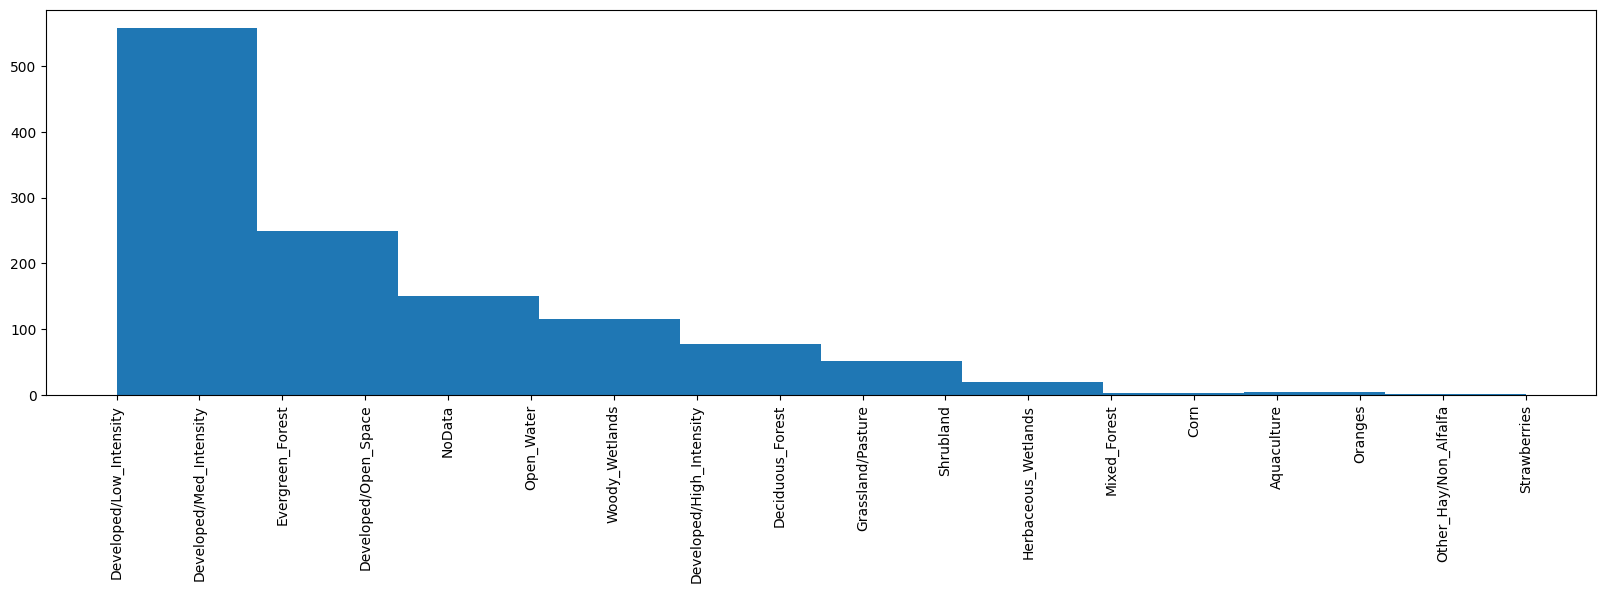

In [27]:
points['crop'].hist(figsize=(20, 5), grid = False)
# Rotate the x-axis labels
_,_ = plt.xticks(rotation=90)

# load the clean data

In [82]:
config.PATH_TO_SAVE_INTERMEDIATORY_INSECT_DATA

PosixPath('/data/Maxent/data/interim')

In [89]:
interim =  os.path.join(config.PATH_TO_SAVE_INTERMEDIATORY_INSECT_DATA, "Brown_Marmorated_Stink_bug_EDD_intermediatory.gpkg")

In [90]:
df_interim = safe_read_file(interim)
df_interim.loc[(df_interim['crop'].isna()) | (df_interim['crop'] == 'NoData'), 'crop'] = df_interim['crop'].mode()[0]

In [91]:
df_interim.shape

(13797, 16)

In [92]:
df_interim['crop'].unique()

array(['Deciduous_Forest', 'Developed/Low_Intensity',
       'Developed/Med_Intensity', 'Other_Hay/Non_Alfalfa',
       'Developed/Open_Space', 'Grassland/Pasture', 'Corn', 'Soybeans',
       'Developed/High_Intensity', 'Fallow/Idle_Cropland',
       'Dbl_Crop_WinWht/Soybeans', 'Shrubland', 'Alfalfa',
       'Evergreen_Forest', 'Woody_Wetlands', 'Herbaceous_Wetlands',
       'Mixed_Forest', 'Blueberries', 'Winter_Wheat', 'Rye', 'Barren',
       'Other_Crops', 'Sod/Grass_Seed', 'Open_Water',
       'Dbl_Crop_WinWht/Corn', 'Cherries', 'Apples', 'Sorghum', 'Oats',
       'Dry_Beans', 'Clover/Wildflowers', 'Herbs', 'Almonds',
       'Other_Tree_Crops', 'Cotton'], dtype=object)

In [93]:
df_crop_data_unavaliable = df_interim[(df_interim['crop'].isna()) | (df_interim['crop'] == 'NoData')]
df_crop_data_unavaliable.shape

(0, 16)

In [78]:
df_interim['crop'].mode()[0]

'Developed/Open_Space'

In [79]:
df_interim[(df_interim['crop'].isna()) | (df_interim['crop'] == 'NoData')]['crop'] = df_interim['crop'].mode()[0]

In [81]:
df_interim['crop'].unique()

array(['Soybeans', 'Grassland/Pasture', 'NoData',
       'Dbl_Crop_WinWht/Soybeans', 'Developed/Open_Space',
       'Deciduous_Forest', 'Corn', 'Barren', 'Cotton', 'Peas',
       'Developed/Low_Intensity', 'Developed/High_Intensity',
       'Woody_Wetlands', 'Evergreen_Forest', 'Dbl_Crop_Barley/Soybeans',
       'Rye', 'Alfalfa', 'Open_Water', 'Sorghum', 'Winter_Wheat',
       'Developed/Med_Intensity', None, 'Fallow/Idle_Cropland',
       'Tomatoes', 'Shrubland', 'Sod/Grass_Seed', 'Misc_Vegs_&_Fruits',
       'Blueberries', 'Dry_Beans', 'Grapes', 'Other_Hay/Non_Alfalfa',
       'Oats', 'Peanuts', 'Squash', 'Other_Crops', 'Potatoes', 'Apples',
       'Watermelons', 'Spring_Wheat', 'Mixed_Forest', 'Greens',
       'Herbaceous_Wetlands', 'Sweet_Corn', 'Christmas_Trees',
       'Sweet_Potatoes', 'Pumpkins', 'Strawberries', 'Barley', 'Rice'],
      dtype=object)